# Minh họa thuật toán PLA (mục 4.2.3): mỗi ô là một lần cập nhật w <- w + y_i x_i

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

Hai nhóm 10 điểm sinh ngẫu nhiên theo phân phối chuẩn

In [2]:
np.random.seed(2)
means = [[-1, 0], [1, 0]]
cov = [[.3, .2], [.2, .3]]
N = 10
X0 = np.random.multivariate_normal(means[0], cov, N)   # lớp +1
X1 = np.random.multivariate_normal(means[1], cov, N)   # lớp -1
X = np.concatenate((X0, X1), axis=0)
y = np.concatenate((np.ones(N), -1 * np.ones(N)))
Xbar = np.concatenate((np.ones((2 * N, 1)), X), axis=1)

def predict(w, Xbar):
    """Dự đoán nhãn +1/-1 (quy ước sgn(0) = 1)."""
    return np.where(Xbar @ w >= 0, 1, -1)

Chạy PLA, lưu lại w trước/sau và điểm bị phân loại sai ở mỗi lần cập nhật

Số lần cập nhật: 4 w = [ 0.5        -2.10128294  1.15004019]


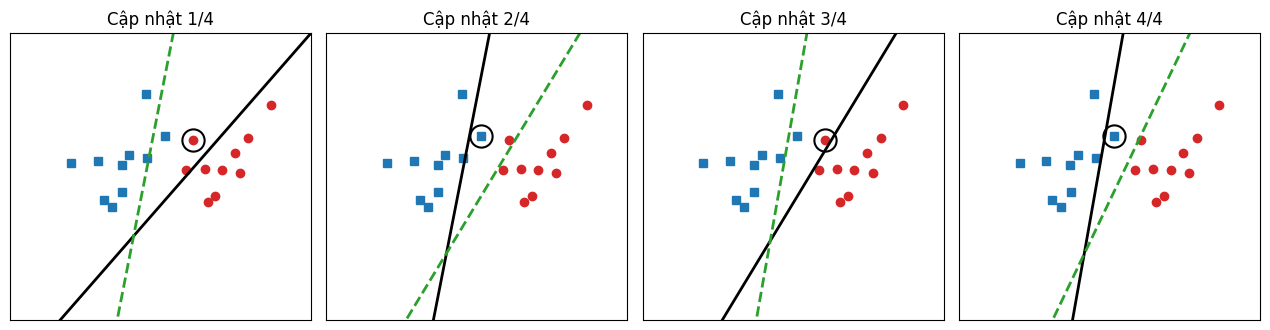

In [3]:
w = np.array([0.5, -1.0, 1.0])
history = []
while True:
    misclassified = np.where(predict(w, Xbar) != y)[0]
    if len(misclassified) == 0:
        break
    i = misclassified[0]                    # lấy điểm sai đầu tiên
    history.append((w.copy(), i, w + y[i] * Xbar[i]))
    w = w + y[i] * Xbar[i]
print("Số lần cập nhật:", len(history), "w =", w)

def draw_line(ax, w, **kw):
    """Vẽ đường thẳng w0 + w1 x1 + w2 x2 = 0."""
    x_line = np.array([-3, 3])
    ax.plot(x_line, -(w[0] + w[1] * x_line) / w[2], **kw)

n_panels = min(len(history), 6)             # vẽ tối đa 6 ô, ô cuối là lần cập nhật cuối
fig, axes = plt.subplots(1, n_panels, figsize=(3.2 * n_panels, 3.4), squeeze=False)
for k, ax in enumerate(axes[0]):
    idx = k if k < n_panels - 1 else len(history) - 1
    w_old, i, w_new = history[idx]
    ax.plot(X0[:, 0], X0[:, 1], "s", color="#1F77B4", ms=6)
    ax.plot(X1[:, 0], X1[:, 1], "o", color="#D62728", ms=6)
    draw_line(ax, w_old, color="black", lw=2)
    draw_line(ax, w_new, color="#2CA02C", lw=2, ls="--")
    ax.plot(X[i, 0], X[i, 1], "o", ms=16, mfc="none", mec="black", mew=1.5)
    ax.set_xlim(-3, 3); ax.set_ylim(-2.5, 2.5)
    ax.set_title(f"Cập nhật {idx + 1}/{len(history)}")
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()
fig.savefig(IMAGES / "pla.png", dpi=150)